In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True

def locate(filename):
    for folder in (Path('.'), Path('../input-data/Project 1 - DTB'), Path('/home/renku/work/input-data/Project 1 - DTB')):
        path = folder / filename
        if path.exists():
            return path
    raise FileNotFoundError(f'Place {filename} next to this notebook or in /mnt/data')

df = pd.read_csv(locate('bioreaction_remaining.csv'))
template = pd.read_csv(locate('bioreaction_template.csv'))
df = df.sort_values(['batch_id', 'elapsed_time']).reset_index(drop=True)
print('Main data:', df.shape, '| Submission template:', template.shape)
display(df.head(8))
print(df.columns.to_list())

Main data: (2858, 12) | Submission template: (156, 6)


,batch_id,elapsed_time,vcd,tcd,substrate,byproduct,feed_substrate,feed_b,feed_c,feed_d,volume,to_predict
0,Batch1,0.000000,0.979690,0.985251,4.507188,0.241840,NaN,NaN,NaN,NaN,10.500750,False
1,Batch1,0.996528,1.909271,1.929805,3.830345,0.940785,NaN,NaN,NaN,NaN,10.494285,False
2,Batch1,1.014977,NaN,NaN,NaN,NaN,NaN,0.062214,NaN,NaN,NaN,False
3,Batch1,1.984722,4.574543,4.611517,2.827742,1.860896,NaN,NaN,NaN,NaN,10.537027,False
4,Batch1,2.044421,NaN,NaN,NaN,NaN,NaN,0.136099,NaN,NaN,NaN,False
5,Batch1,2.722998,NaN,NaN,NaN,NaN,NaN,NaN,0.000854,NaN,NaN,False
6,Batch1,2.967361,7.489739,7.545903,2.362482,1.941632,NaN,NaN,NaN,NaN,10.695897,False
7,Batch1,2.981134,NaN,NaN,NaN,NaN,NaN,0.271894,NaN,NaN,NaN,False


['batch_id', 'elapsed_time', 'vcd', 'tcd', 'substrate', 'byproduct', 'feed_substrate', 'feed_b', 'feed_c', 'feed_d', 'volume', 'to_predict']


### Feature Dictionary
| Column | Meaning | Role |
|:--|:--|:--|
| `batch_id` | Unique cell culture run | Grouping identifier, not a numerical feature |
| `elapsed_time` | Time since run start (slide plots use days; verify CSV units) | Time coordinate |
| `vcd` | Viable cell density, living cells per culture volume | Prediction target |
| `tcd` | Total cell density, living and dead cells | Prediction target |
| `substrate` | Concentration of a nutrient/substrate | Prediction target |
| `byproduct` | Concentration of a metabolic byproduct | Prediction target |
| `feed_substrate` | Recorded substrate feed event | Process input |
| `feed_b`, `feed_c`, `feed_d` | Other three recorded feed streams | Process inputs |
| `volume` | Culture volume observation | Process state / available input |
| `to_predict` | Marks rows whose four biological targets must be predicted | Evaluation mask, never a predictive input |


### Further Exploration

In [3]:
print('Data types:')
display(df.dtypes.rename('dtype').to_frame())
print('Observed entries per column:')
display(pd.DataFrame({'observed': df.notna().sum(), 'missing': df.isna().sum(), 'missing_%': (100*df.isna().mean()).round(1)}))
print('Batches:', df.batch_id.nunique())
print('Rows flagged for prediction:', int(df.to_predict.sum()))
print('Time range:', df.elapsed_time.min(), 'to', df.elapsed_time.max())
print('Repeated (batch, time) pairs:', int(df.duplicated(['batch_id','elapsed_time']).sum()))

Data types:


,dtype
batch_id,str
elapsed_time,float64
vcd,float64
tcd,float64
substrate,float64
byproduct,float64
feed_substrate,float64
feed_b,float64
feed_c,float64
feed_d,float64


Observed entries per column:


,observed,missing,missing_%
batch_id,2858,0,0.0
elapsed_time,2858,0,0.0
vcd,698,2160,75.6
tcd,698,2160,75.6
substrate,698,2160,75.6
byproduct,698,2160,75.6
feed_substrate,132,2726,95.4
feed_b,732,2126,74.4
feed_c,957,1901,66.5
feed_d,183,2675,93.6


Batches: 61
Rows flagged for prediction: 156
Time range: 0.0 to 13.0006944444394
Repeated (batch, time) pairs: 0


,rows
Columns recorded together,
feed_c,957
feed_b,732
"vcd, tcd, substrate, byproduct, volume",698
feed_d,183
feed_substrate,132


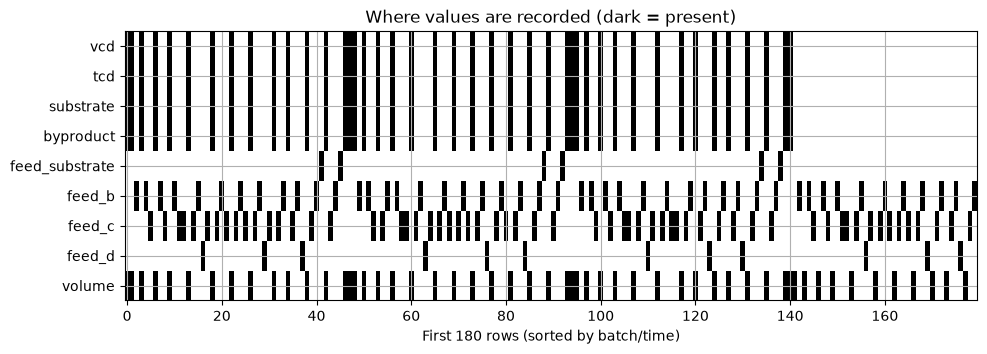

In [4]:
targets = ['vcd','tcd','substrate','byproduct']
feeds = ['feed_substrate','feed_b','feed_c','feed_d']
observed = df.loc[~df.to_predict].copy()
patterns = observed[targets + feeds + ['volume']].notna().astype(int)
pattern_names = patterns.apply(lambda row: ', '.join(row.index[row.eq(1)]) or 'none', axis=1)
display(pattern_names.value_counts().head(15).rename_axis('Columns recorded together').to_frame('rows'))
fig, ax = plt.subplots(figsize=(11,3.5))
ax.imshow(df[targets+feeds+['volume']].notna().iloc[:180].T, aspect='auto', interpolation='nearest', cmap='Greys')
ax.set_yticks(range(9), targets+feeds+['volume']); ax.set_xlabel('First 180 rows (sorted by batch/time)')
ax.set_title('Where values are recorded (dark = present)'); plt.show()

In [5]:
heldout_ids = set(df.loc[df.to_predict,'batch_id'])
train_ids = set(df.batch_id) - heldout_ids
print('Fully observed batches:', len(train_ids))
print('Batches with hidden prediction rows:', len(heldout_ids))
print('Prediction rows per held-out batch:')
display(df.loc[df.to_predict].groupby('batch_id').size().to_frame('rows_to_predict'))
print('Template columns:', template.columns.tolist())
print('Template rows:', len(template))
print('Prediction row keys match template (rounded to 6 decimals):', set(map(tuple, df.loc[df.to_predict, ['batch_id','elapsed_time']].assign(elapsed_time=lambda x: x.elapsed_time.round(6)).to_numpy())) == set(map(tuple,template[['batch_id','elapsed_time']].assign(elapsed_time=lambda x: x.elapsed_time.round(6)).to_numpy())))

Fully observed batches: 49
Batches with hidden prediction rows: 12
Prediction rows per held-out batch:


,rows_to_predict
batch_id,
Batch12,13
Batch24,13
Batch32,13
Batch35,13
Batch40,13
Batch48,13
Batch5,13
Batch54,13
Batch56,13


Template columns: ['batch_id', 'elapsed_time', 'vcd', 'tcd', 'substrate', 'byproduct']
Template rows: 156
Prediction row keys match template (rounded to 6 decimals): True


### Summary statistics for the four biological targets

,count,mean,std,min,25%,50%,75%,max
vcd,698.0,19.001,10.752,0.855,8.625,22.932,27.326,39.382
tcd,698.0,19.810,11.261,0.864,8.672,24.179,28.534,40.106
substrate,698.0,2.493,1.026,0.314,1.923,2.383,2.889,4.993
byproduct,698.0,1.405,0.789,0.231,0.709,1.276,2.100,3.030


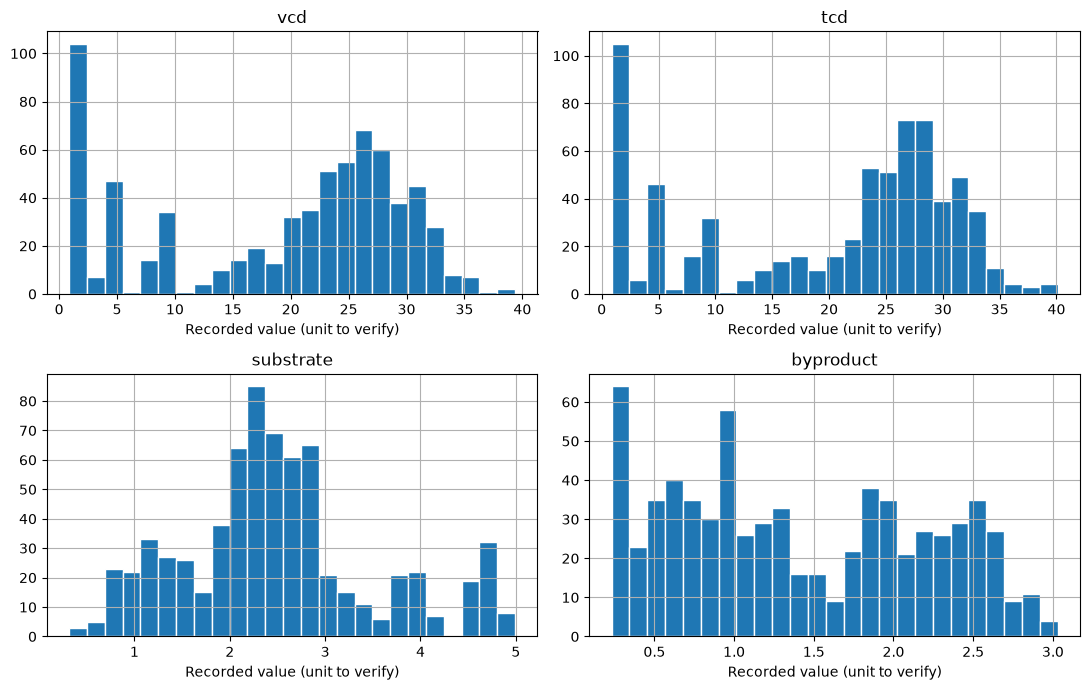

In [6]:
lab = df.loc[(~df.to_predict) & df[targets].notna().any(axis=1)].copy()
display(lab[targets].describe().T.round(3))
fig, axs = plt.subplots(2,2,figsize=(11,7))
for ax,col in zip(axs.flat,targets):
    ax.hist(lab[col].dropna(),bins=25,edgecolor='white')
    ax.set_title(col);ax.set_xlabel('Recorded value (unit to verify)')
plt.tight_layout();plt.show()

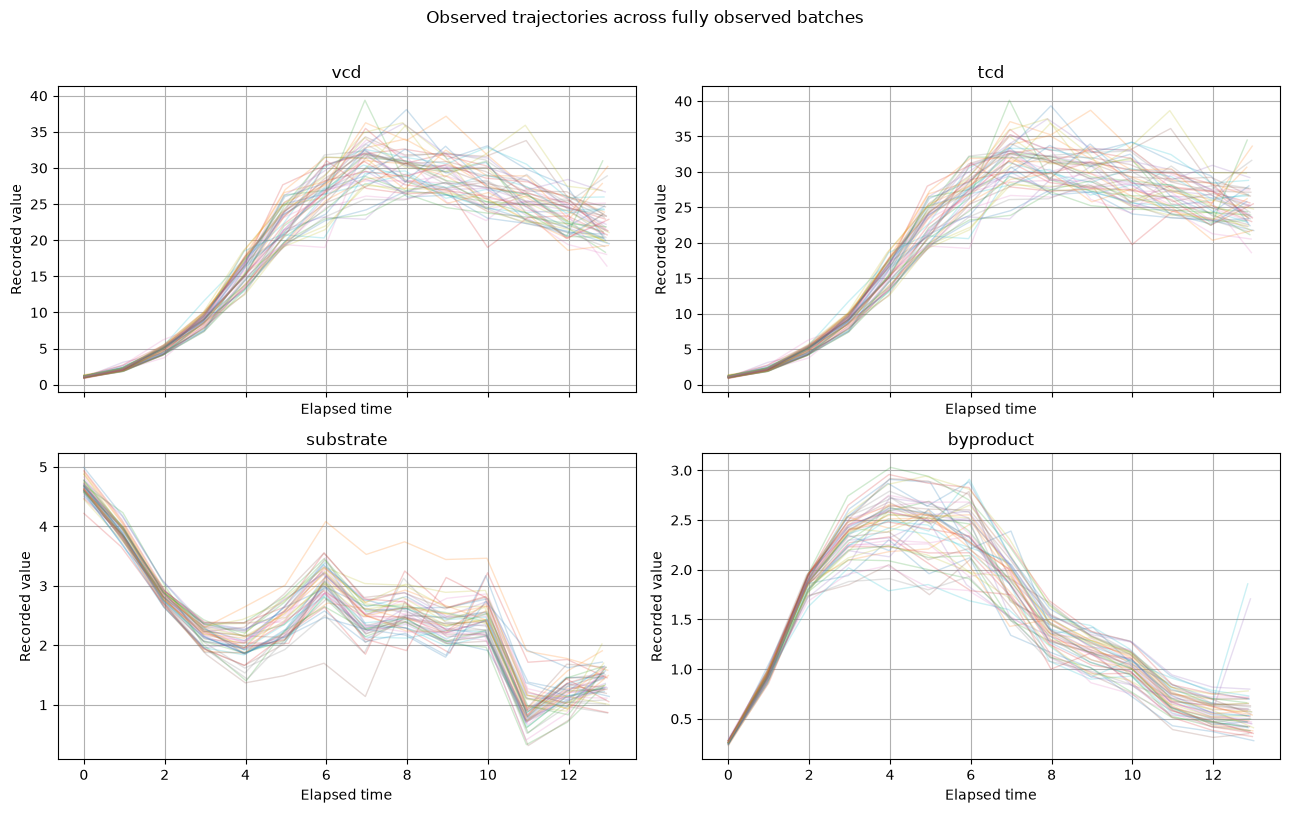

In [22]:
train_lab = lab[lab.batch_id.isin(train_ids)].copy()
fig,axs=plt.subplots(2,2,figsize=(13,8),sharex=True)
for ax,col in zip(axs.flat,targets):
    for bid,g in train_lab.groupby('batch_id'):
        g=g.dropna(subset=[col]).sort_values('elapsed_time')
        ax.plot(g.elapsed_time,g[col],alpha=.22,lw=1)
    ax.set_title(col);ax.set_ylabel('Recorded value')
    ax.set_xlabel('Elapsed time')
plt.suptitle('Observed trajectories across fully observed batches',y=1.01)
plt.tight_layout();plt.show()

Rows with TCD < VCD: 0


,count,mean,std,min,25%,50%,75%,max
viability,686.0,0.967,0.031,0.843,0.954,0.980,0.99,0.999
dead_cell_density,686.0,0.822,0.871,0.001,0.077,0.521,1.32,4.111


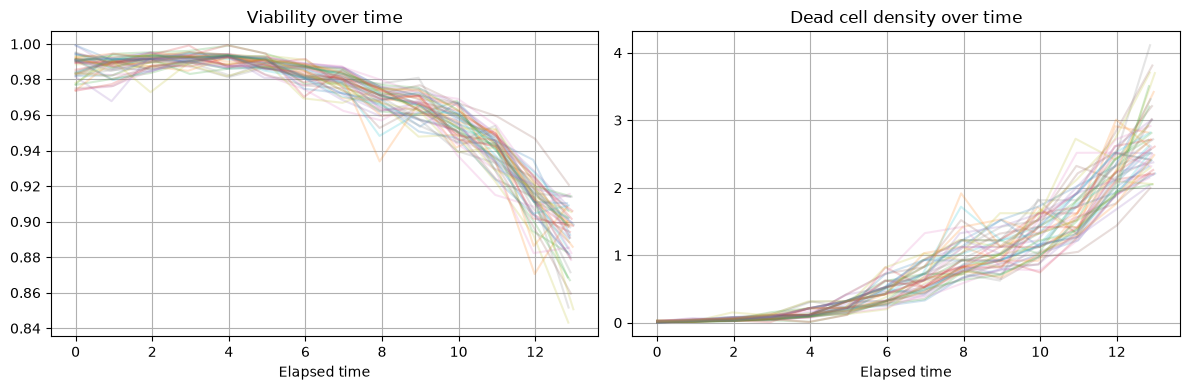

In [8]:
cells = train_lab.dropna(subset=['vcd','tcd']).copy()
cells['viability'] = np.where(cells.tcd>0,cells.vcd/cells.tcd,np.nan)
cells['dead_cell_density'] = cells.tcd-cells.vcd
print('Rows with TCD < VCD:',int((cells.tcd < cells.vcd).sum()))
display(cells[['viability','dead_cell_density']].describe().T.round(3))
fig,axs=plt.subplots(1,2,figsize=(12,4))
for bid,g in cells.groupby('batch_id'):
    axs[0].plot(g.elapsed_time,g.viability,alpha=.2)
    axs[1].plot(g.elapsed_time,g.dead_cell_density,alpha=.2)
axs[0].set_title('Viability over time');axs[1].set_title('Dead cell density over time')
for ax in axs: ax.set_xlabel('Elapsed time')
plt.tight_layout();plt.show()

### Explore the four feed streams
A feed entry is an event, not necessarily a daily measurement. Compare event frequency, magnitude, and timing. Cumulative sums are meaningful only if the recorded feed entries are additive quantities; confirm the feed semantics before calculating physical cumulative doses.

,feed,events,min,median,max,negative_events
0,feed_substrate,132,0.0501,0.0654,0.0993,0
1,feed_b,732,0.0424,0.5225,0.9696,0
2,feed_c,957,0.0008,0.0018,0.0020,0
3,feed_d,183,0.0103,0.0163,0.0175,0


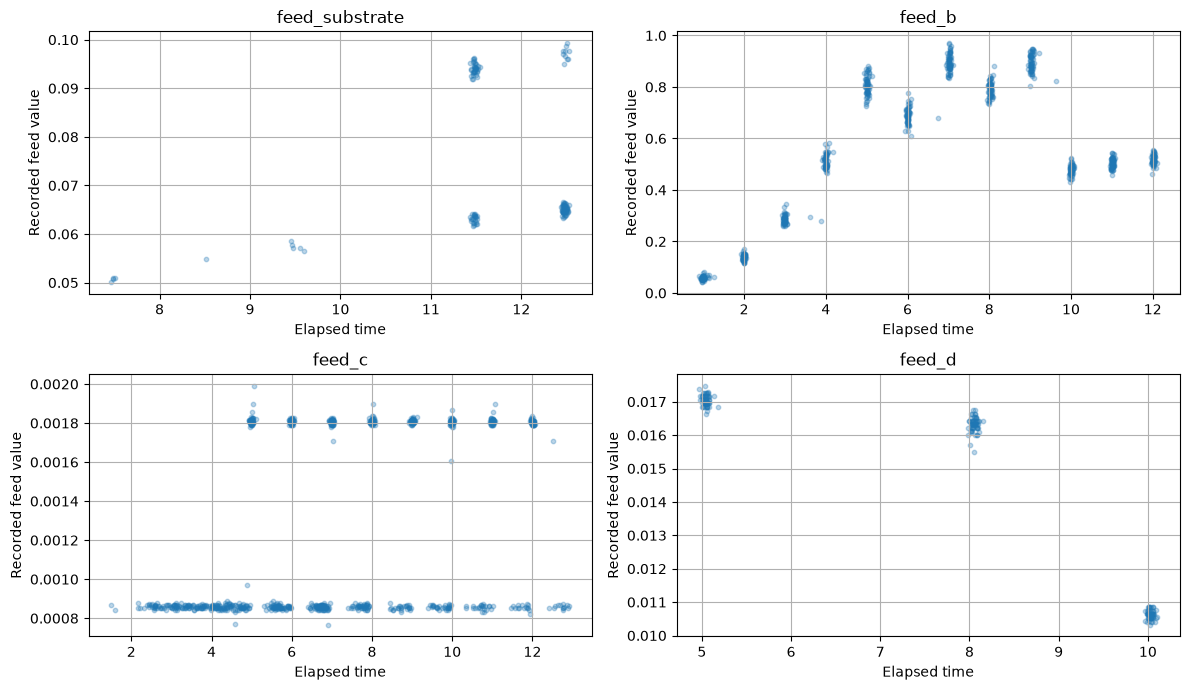

In [9]:
feed_summary=[]
for col in feeds:
    s=df[col].dropna()
    feed_summary.append({'feed':col,'events':len(s),'min':s.min(),'median':s.median(),'max':s.max(),'negative_events':int((s<0).sum())})
display(pd.DataFrame(feed_summary).round(4))
fig,axs=plt.subplots(2,2,figsize=(12,7))
for ax,col in zip(axs.flat,feeds):
    events=df.loc[df[col].notna(),['elapsed_time',col]]
    ax.scatter(events.elapsed_time,events[col],s=10,alpha=.3)
    ax.set_title(col);ax.set_xlabel('Elapsed time');ax.set_ylabel('Recorded feed value')
plt.tight_layout();plt.show()

### Inspect a single batch as an event timeline
This is the most useful plot for understanding the raw table. Each marker means that an event or measurement exists at that timestamp, not that the other variables are zero.

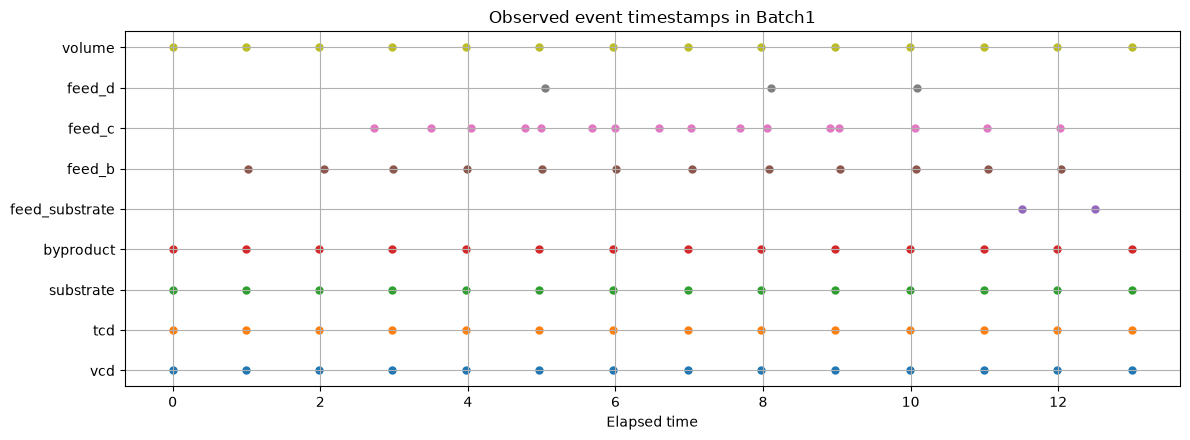

,batch_id,elapsed_time,vcd,tcd,substrate,byproduct,feed_substrate,feed_b,feed_c,feed_d,volume,to_predict
0,Batch1,0.000000,0.979690,0.985251,4.507188,0.241840,NaN,NaN,NaN,NaN,10.500750,False
1,Batch1,0.996528,1.909271,1.929805,3.830345,0.940785,NaN,NaN,NaN,NaN,10.494285,False
2,Batch1,1.014977,NaN,NaN,NaN,NaN,NaN,0.062214,NaN,NaN,NaN,False
3,Batch1,1.984722,4.574543,4.611517,2.827742,1.860896,NaN,NaN,NaN,NaN,10.537027,False
4,Batch1,2.044421,NaN,NaN,NaN,NaN,NaN,0.136099,NaN,NaN,NaN,False
5,Batch1,2.722998,NaN,NaN,NaN,NaN,NaN,NaN,0.000854,NaN,NaN,False
6,Batch1,2.967361,7.489739,7.545903,2.362482,1.941632,NaN,NaN,NaN,NaN,10.695897,False
7,Batch1,2.981134,NaN,NaN,NaN,NaN,NaN,0.271894,NaN,NaN,NaN,False
8,Batch1,3.501829,NaN,NaN,NaN,NaN,NaN,NaN,0.000863,NaN,NaN,False
9,Batch1,3.970833,14.300371,14.405872,2.263021,2.301048,NaN,NaN,NaN,NaN,10.946566,False


In [10]:
example_batch = sorted(train_ids, key=lambda x: int(''.join(filter(str.isdigit,x)) or 0))[0]
g=df[df.batch_id.eq(example_batch)].sort_values('elapsed_time')
columns=targets+feeds+['volume']
fig,ax=plt.subplots(figsize=(12,4.5))
for i,col in enumerate(columns):
    times=g.loc[g[col].notna(),'elapsed_time']
    ax.scatter(times,np.full(len(times),i),s=25,label=col)
ax.set_yticks(range(len(columns)),columns);ax.set_xlabel('Elapsed time')
ax.set_title(f'Observed event timestamps in {example_batch}');plt.tight_layout();plt.show()
display(g.head(20))

### Culture volume

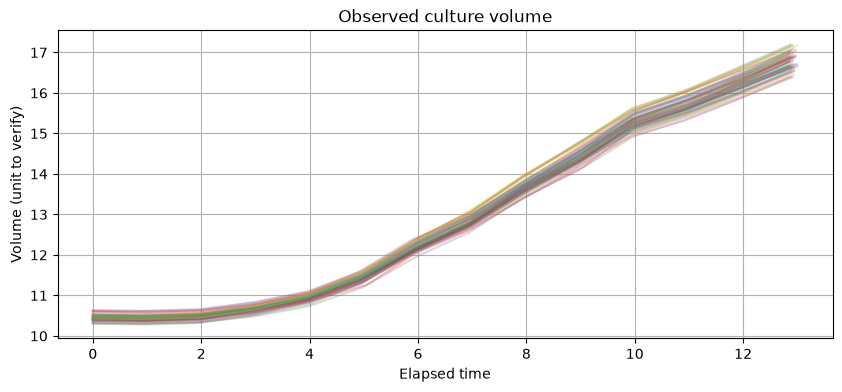

,count,mean,std,min,25%,50%,75%,max
volume,854.0,12.978,2.29,10.281,10.658,12.475,15.284,17.196


In [11]:
fig,ax=plt.subplots(figsize=(10,4))
for bid,g in df[df.batch_id.isin(train_ids) & df.volume.notna()].groupby('batch_id'):
    ax.plot(g.elapsed_time,g.volume,alpha=.3)
ax.set(title='Observed culture volume',xlabel='Elapsed time',ylabel='Volume (unit to verify)')
plt.show()
display(df.volume.describe().to_frame('volume').T.round(3))

### Compare starting conditions across batches

,batch_id,elapsed_time,vcd,tcd,substrate,byproduct,split
0,Batch1,0.0,0.979690,0.985251,4.507188,0.241840,fully observed
1,Batch10,0.0,1.125885,1.145220,4.628973,0.280303,fully observed
2,Batch11,0.0,1.229273,1.258263,4.767697,0.270462,fully observed
3,Batch12,0.0,1.271395,1.291243,4.750748,0.270885,held-out
4,Batch13,0.0,0.863322,0.872388,4.588821,0.241468,fully observed
5,Batch14,0.0,0.984811,0.994140,4.714830,0.279082,fully observed
6,Batch15,0.0,1.151744,1.171347,4.600686,0.281736,fully observed
7,Batch16,0.0,1.025715,1.031506,4.623306,0.259056,fully observed
8,Batch17,0.0,1.197585,1.216976,4.680119,0.281715,fully observed
9,Batch18,0.0,0.993540,1.005038,4.452095,0.231040,fully observed


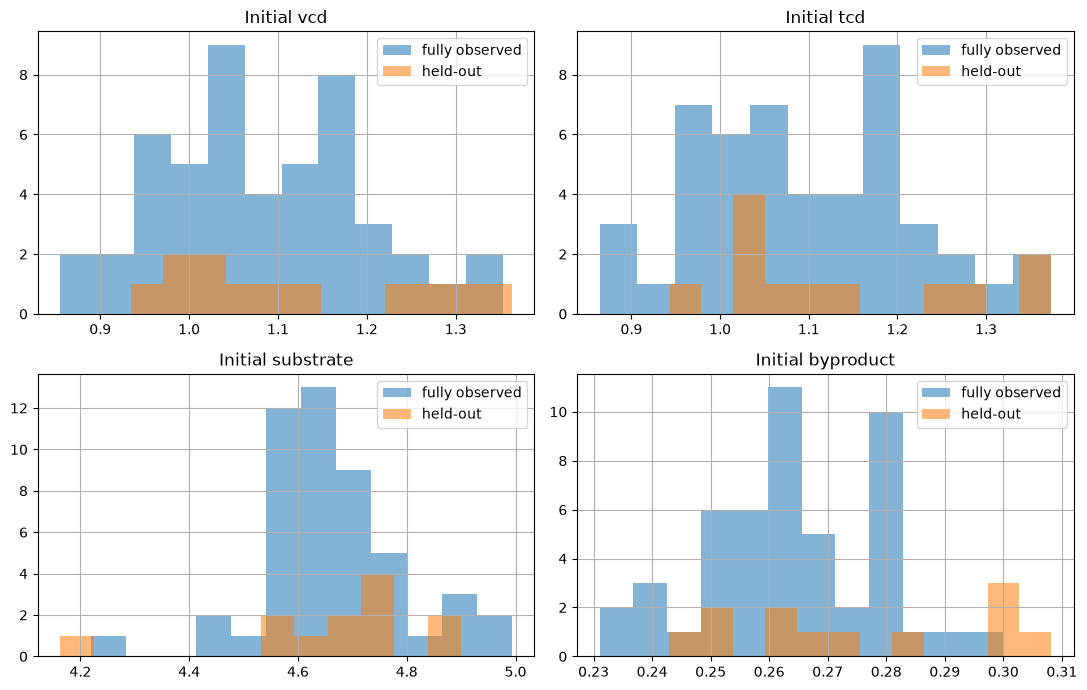

In [12]:
initial = (lab.sort_values(['batch_id','elapsed_time'])
           .groupby('batch_id',as_index=False).first()[['batch_id','elapsed_time']+targets])
initial['split'] = np.where(initial.batch_id.isin(heldout_ids),'held-out','fully observed')
display(initial.head(10))
fig,axs=plt.subplots(2,2,figsize=(11,7))
for ax,col in zip(axs.flat,targets):
    for split,g in initial.groupby('split'):
        ax.hist(g[col].dropna(),bins=12,alpha=.55,label=split)
    ax.set_title('Initial '+col);ax.legend()
plt.tight_layout();plt.show()

### Compare starting conditions across batches

Day-zero values may explain differences in later trajectories. For each batch, use the earliest observed target measurement as its starting state, and record its timestamp rather than assuming it is exactly zero.

,batch_id,elapsed_time,vcd,tcd,substrate,byproduct,split
0,Batch1,0.0,0.979690,0.985251,4.507188,0.241840,fully observed
1,Batch10,0.0,1.125885,1.145220,4.628973,0.280303,fully observed
2,Batch11,0.0,1.229273,1.258263,4.767697,0.270462,fully observed
3,Batch12,0.0,1.271395,1.291243,4.750748,0.270885,held-out
4,Batch13,0.0,0.863322,0.872388,4.588821,0.241468,fully observed
5,Batch14,0.0,0.984811,0.994140,4.714830,0.279082,fully observed
6,Batch15,0.0,1.151744,1.171347,4.600686,0.281736,fully observed
7,Batch16,0.0,1.025715,1.031506,4.623306,0.259056,fully observed
8,Batch17,0.0,1.197585,1.216976,4.680119,0.281715,fully observed
9,Batch18,0.0,0.993540,1.005038,4.452095,0.231040,fully observed


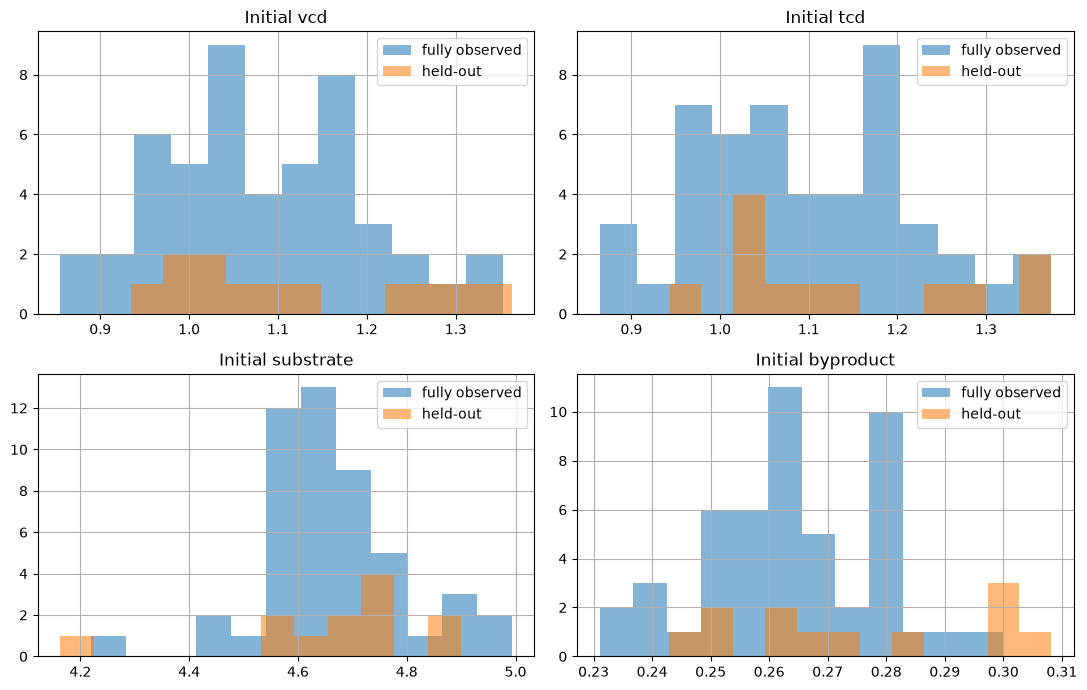

In [13]:
initial = (lab.sort_values(['batch_id','elapsed_time'])
           .groupby('batch_id',as_index=False).first()[['batch_id','elapsed_time']+targets])
initial['split'] = np.where(initial.batch_id.isin(heldout_ids),'held-out','fully observed')
display(initial.head(10))
fig,axs=plt.subplots(2,2,figsize=(11,7))
for ax,col in zip(axs.flat,targets):
    for split,g in initial.groupby('split'):
        ax.hist(g[col].dropna(),bins=12,alpha=.55,label=split)
    ax.set_title('Initial '+col);ax.legend()
plt.tight_layout();plt.show()

In [18]:


targets = ["vcd", "tcd", "substrate", "byproduct"]

# Count rows where all four targets are available
df["fully_observed"] = df[targets].notna().all(axis=1)

# Group by batch
batch_counts = df.groupby("batch_id").agg(
    observed=("fully_observed", "sum"),
    to_predict=("to_predict", "sum")
)

batch_counts.head(10)

,observed,to_predict
batch_id,,
Batch1,14,0
Batch10,14,0
Batch11,14,0
Batch12,1,13
Batch13,14,0
Batch14,14,0
Batch15,14,0
Batch16,14,0
Batch17,14,0


In [20]:


# Count rows where all four targets are available
df["fully_observed"] = df[targets].notna().all(axis=1)

# Group by batch
batch_counts = df.groupby("batch_id").agg(
    observed=("fully_observed", "sum"),
    to_predict=("to_predict", "sum")
)

batch_counts.head(61)

,observed,to_predict
batch_id,,
Batch1,14,0
Batch10,14,0
Batch11,14,0
Batch12,1,13
Batch13,14,0
...,...,...
Batch60,1,13
Batch61,14,0
Batch7,14,0


In [21]:
print(batch_counts.sum())

print("\nBatches requiring predictions:")
display(batch_counts[batch_counts["to_predict"] > 0])

observed      698
to_predict    156
dtype: int64

Batches requiring predictions:


,observed,to_predict
batch_id,,
Batch12,1,13
Batch24,1,13
Batch32,1,13
Batch35,1,13
Batch40,1,13
Batch48,1,13
Batch5,1,13
Batch54,1,13
Batch56,1,13


,vcd,tcd,substrate,byproduct
vcd,1.000,0.998,-0.570,0.120
tcd,0.998,1.000,-0.594,0.077
substrate,-0.570,-0.594,1.000,-0.078
byproduct,0.120,0.077,-0.078,1.000


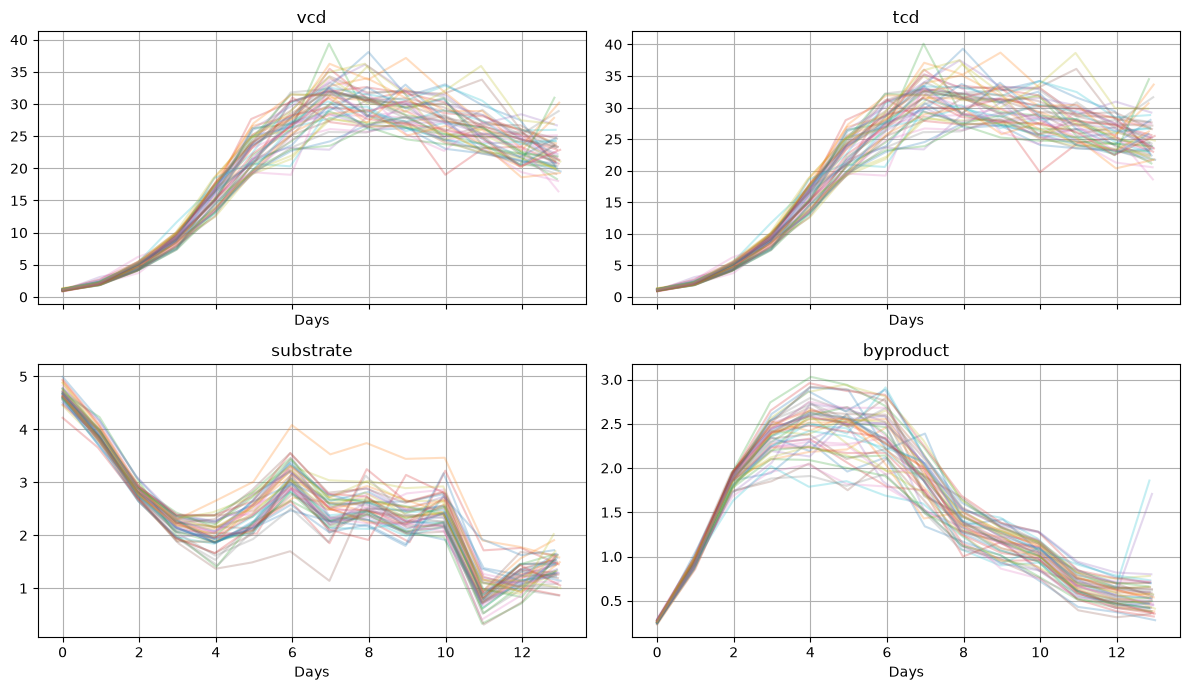

In [23]:
observed = df[df[targets].notna().all(axis=1)].copy()
display(observed[targets].corr().round(3))
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, target in zip(axes.ravel(), targets):
    for _, batch in observed.groupby("batch_id"):
        if len(batch) > 1:
            ax.plot(batch.elapsed_time, batch[target], alpha=0.25)
    ax.set_title(target)
    ax.set_xlabel("Days")
plt.tight_layout(); plt.show()

count    698.000000
mean       0.967141
std        0.031164
min        0.843162
25%        0.954052
50%        0.980810
75%        0.989932
max        0.999299
Name: viability, dtype: float64


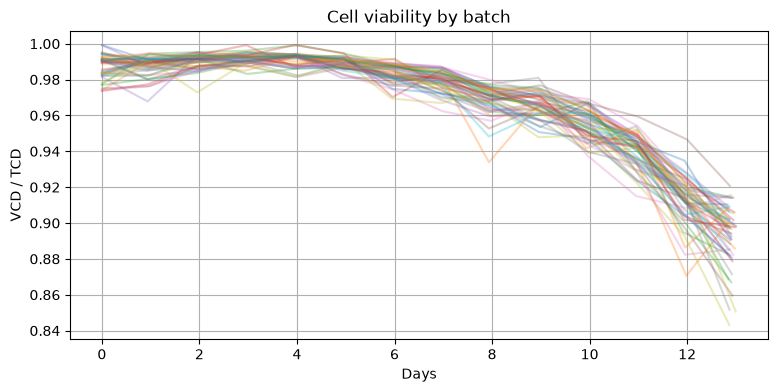

In [24]:
observed["viability"] = observed.vcd / observed.tcd
print(observed.viability.describe())
fig, ax = plt.subplots(figsize=(9, 4))
for _, batch in observed.groupby("batch_id"):
    if len(batch)>1: ax.plot(batch.elapsed_time, batch.viability, alpha=.3)
ax.set(xlabel="Days", ylabel="VCD / TCD", title="Cell viability by batch")
plt.show()

In [25]:
def make_features(raw):
    rows = []
    for batch_id, g in raw.groupby("batch_id", sort=False):
        g = g.sort_values("elapsed_time")
        measured = g[g[targets].notna().all(axis=1)]
        initial = measured.iloc[0]
        prediction_times = g[g[targets].notna().all(axis=1) | g.to_predict]
        for _, r in prediction_times.iterrows():
            x = {"batch_id": batch_id, "elapsed_time": r.elapsed_time,
                 "to_predict": bool(r.to_predict)}
            for target in targets:
                x[target] = r[target]
                x["initial_" + target] = initial[target]
            for feed in feeds:
                events = g.loc[g.elapsed_time <= r.elapsed_time, ["elapsed_time", feed]].dropna()
                x["cum_" + feed] = events[feed].sum()
                x["count_" + feed] = len(events)
                x["last_" + feed] = events.elapsed_time.iloc[-1] if len(events) else 0
            volume = g.loc[g.elapsed_time <= r.elapsed_time, "volume"].dropna()
            x["volume"] = volume.iloc[-1] if len(volume) else initial.volume
            rows.append(x)
    return pd.DataFrame(rows)

features = make_features(df)
feature_cols = [c for c in features if c not in ["batch_id", "to_predict"] + targets]
heldout_ids = set(df.loc[df.to_predict, "batch_id"])
train = features[(~features.batch_id.isin(heldout_ids)) & (features.elapsed_time > 0)].copy()
print("Training rows:", len(train), "Training batches:", train.batch_id.nunique())
display(train[feature_cols].head())

Training rows: 637 Training batches: 49


,elapsed_time,initial_vcd,initial_tcd,initial_substrate,initial_byproduct,cum_feed_substrate,count_feed_substrate,last_feed_substrate,cum_feed_b,count_feed_b,last_feed_b,cum_feed_c,count_feed_c,last_feed_c,cum_feed_d,count_feed_d,last_feed_d,volume
1,0.996528,0.97969,0.985251,4.507188,0.24184,0.0,0,0.0,0.000000,0,0.000000,0.000000,0,0.000000,0.0,0,0.0,10.494285
2,1.984722,0.97969,0.985251,4.507188,0.24184,0.0,0,0.0,0.062214,1,1.014977,0.000000,0,0.000000,0.0,0,0.0,10.537027
3,2.967361,0.97969,0.985251,4.507188,0.24184,0.0,0,0.0,0.198313,2,2.044421,0.000854,1,2.722998,0.0,0,0.0,10.695897
4,3.970833,0.97969,0.985251,4.507188,0.24184,0.0,0,0.0,0.470207,3,2.981134,0.001718,2,3.501829,0.0,0,0.0,10.946566
5,4.963889,0.97969,0.985251,4.507188,0.24184,0.0,0,0.0,0.964163,4,3.993079,0.003447,4,4.777384,0.0,0,0.0,11.417555


In [27]:
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error

In [28]:
def mean_trajectory_predict(fold_train, fold_test, target):
    # Pool trajectories by rounded day; interpolate mean onto requested timestamps
    reference = fold_train.assign(day=fold_train.elapsed_time.round().astype(int))
    means = reference.groupby("day")[target].mean().sort_index()
    return np.interp(fold_test.elapsed_time, means.index.to_numpy(), means.to_numpy())

cv = GroupKFold(n_splits=5)
results = []
oof = {}
for target in targets:
    y = train[target].to_numpy()
    baseline_pred = np.zeros(len(train))
    ml_pred = np.zeros(len(train))
    for tr_idx, val_idx in cv.split(train, groups=train.batch_id):
        tr, val = train.iloc[tr_idx], train.iloc[val_idx]
        baseline_pred[val_idx] = mean_trajectory_predict(tr, val, target)
        model = ExtraTreesRegressor(n_estimators=150, min_samples_leaf=3,
                                    max_features=0.9, random_state=42, n_jobs=-1)
        model.fit(tr[feature_cols], tr[target])
        ml_pred[val_idx] = model.predict(val[feature_cols])
    oof[target] = (y, baseline_pred, ml_pred)
    results.append({"target": target,
                    "mean_trajectory_MAE": mean_absolute_error(y, baseline_pred),
                    "ExtraTrees_MAE": mean_absolute_error(y, ml_pred)})
display(pd.DataFrame(results).round(4))

,target,mean_trajectory_MAE,ExtraTrees_MAE
0,vcd,1.7888,1.4123
1,tcd,1.8706,1.4508
2,substrate,0.2136,0.2131
3,byproduct,0.1487,0.1509


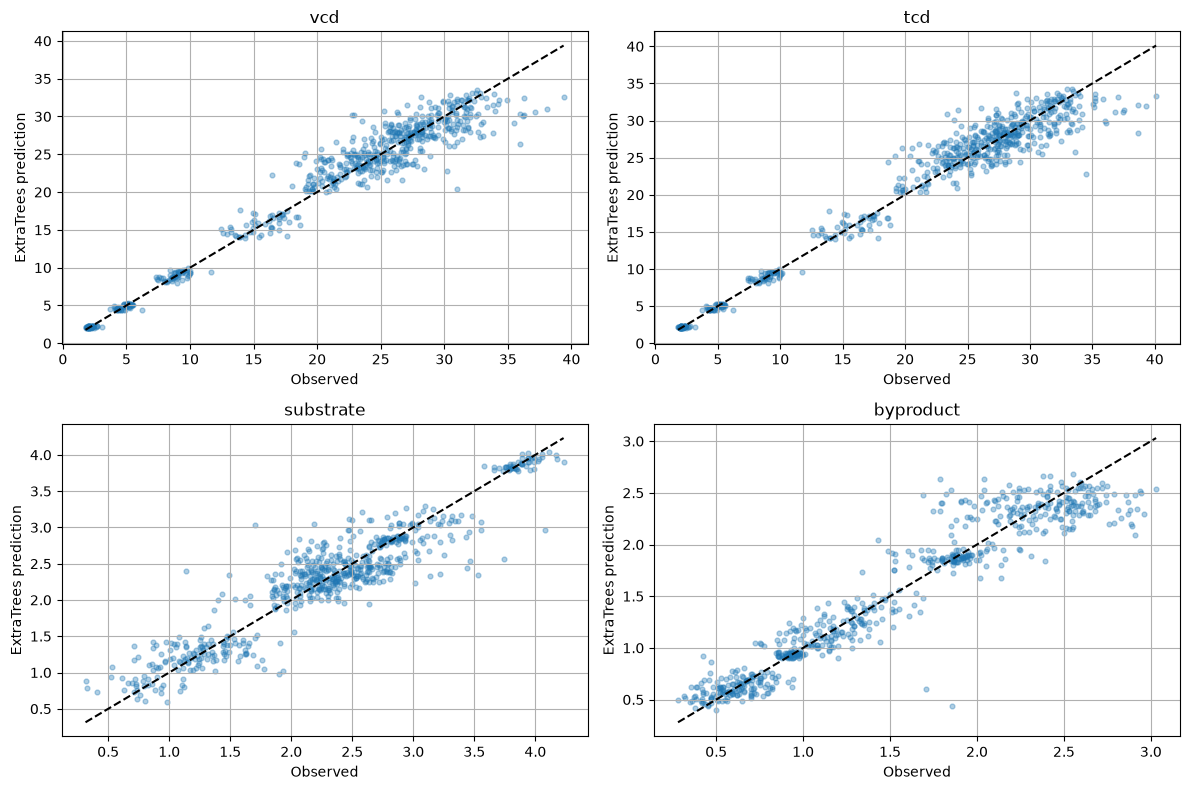

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, target in zip(axes.ravel(), targets):
    y, baseline, ml = oof[target]
    ax.scatter(y, ml, alpha=.35, s=12)
    low, high = min(y.min(), ml.min()), max(y.max(), ml.max())
    ax.plot([low, high], [low, high], linestyle="--", color="black")
    ax.set(xlabel="Observed", ylabel="ExtraTrees prediction", title=target)
plt.tight_layout(); plt.show()